In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [37]:
df = pd.read_csv("customers.csv")




In [38]:
df.head()

,age,annual_spend,purchase_freq
0,31.0,1209.59,43
1,40.5,1703.79,25
2,48.5,1254.98,46
3,51.8,1341.83,30
4,37.1,1892.70,30


In [39]:
df.describe()

,age,annual_spend,purchase_freq
count,200.000000,200.000000,200.000000
mean,63.144500,4180.670350,51.350000
std,12.343675,2471.888556,25.699021
min,27.600000,885.160000,1.000000
25%,64.725000,2161.835000,31.000000
50%,70.000000,3574.885000,49.500000
75%,70.000000,5960.895000,71.250000
max,70.000000,11931.690000,114.000000


The dataset contains 200 customers and three features: age, annual_spend, and purchase_freq. Summary statistics help us understand the distribution and range of each feature. Missing values are checked before applying clustering algorithms.

In [40]:
df.shape

(200, 3)

In [41]:
df.isnull().sum()

age              0
annual_spend     0
purchase_freq    0
dtype: int64

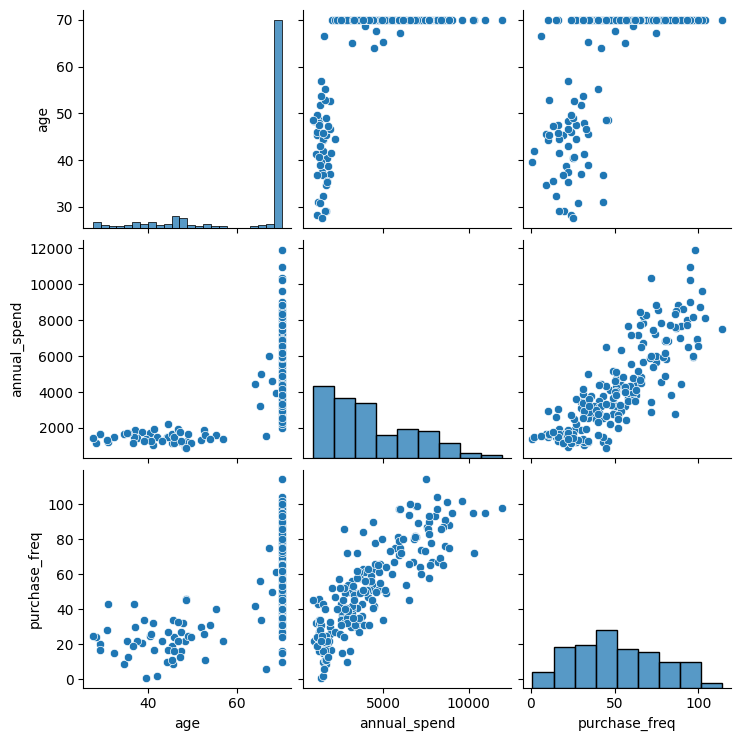

In [42]:
sns.pairplot(df)
plt.show()

The pairplot shows the distribution of each feature and the relationships between different features. Annual spending and purchase frequency show a positive relationship. The plots suggest possible customer groupings, which will be examined using clustering algorithms.

In [43]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

X_scaled.shape

(200, 3)

Standardization converts each feature to approximately zero mean and unit standard deviation. Annual spending has much larger numerical values than age and purchase frequency. Scaling prevents annual spending from dominating the distance calculations during clustering.

In [44]:
wcss = []
sil = []

for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)

    wcss.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, labels))




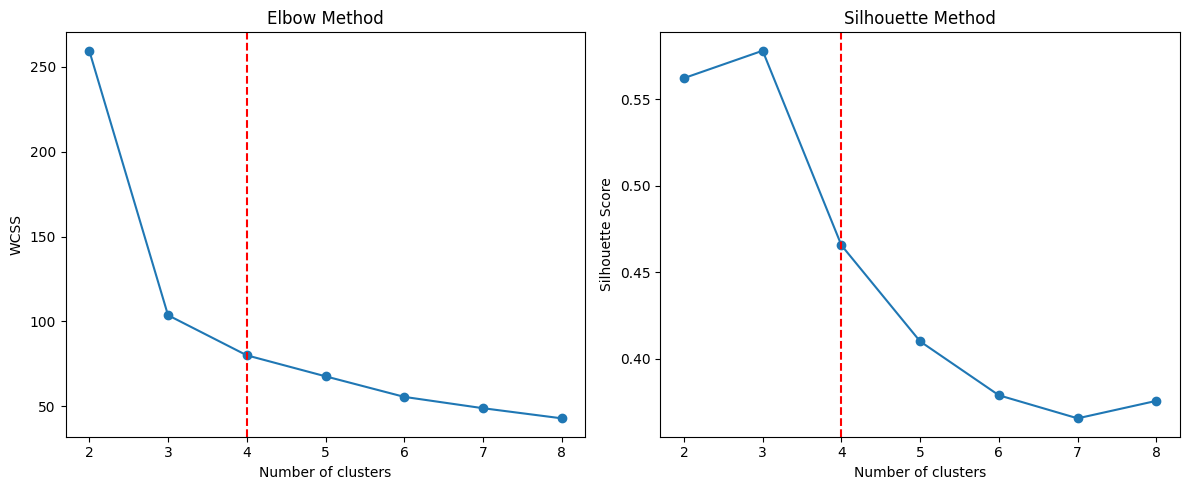

Silhouette scores: [0.5622255105993736, 0.578096258581501, 0.4655854835976729, 0.4099705730938743, 0.378813626759555, 0.36547373631457164, 0.3755920139128838]


In [45]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(2, 9), wcss, marker="o")
plt.axvline(4, color="red", linestyle="--")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.subplot(1, 2, 2)
plt.plot(range(2, 9), sil, marker="o")
plt.axvline(4, color="red", linestyle="--")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Method")

plt.tight_layout()
plt.show()

print("Silhouette scores:", sil)

The elbow method helps identify where the decrease in WCSS begins to slow down. The silhouette score measures how well the clusters are separated. The silhouette score is highest at k=3.. i am using 4 as told to follow in assignment 

In [ ]:
def kmeans_scratch(X, k, max_iter=300, seed=42):
    np.random.seed(seed)
    centroids = X[np.random.choice(len(X), k, replace=False)]
    for i in range(max_iter):
        dist = np.linalg.norm(X[:, None] - centroids, axis=2)
        labels = np.argmin(dist, axis=1)
        new_centroids = centroids.copy()
        for j in range(k):
            if np.sum(labels == j) > 0:
                new_centroids[j] = X[labels == j].mean(axis=0)

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    dist = np.linalg.norm(X[:, None] - centroids, axis=2)
    labels = np.argmin(dist, axis=1)
    wcss = np.sum((X - centroids[labels]) ** 2)

    return labels, centroids, wcss

In [47]:
labels1, centroids, wcss1 = kmeans_scratch(X_scaled, 4)

print(wcss1)


90.47460146635768


In [48]:

print(centroids)

[[ 0.55292503  1.29321213  1.22672075]
 [-2.23152899 -1.08940116 -1.13784009]
 [-1.16471929 -1.10811268 -1.0836319 ]
 [ 0.53937584 -0.23412676 -0.186839  ]]


In [49]:
km = KMeans(n_clusters=4, n_init=10, random_state=42)
labels2 = km.fit_predict(X_scaled)

wcss2 = km.inertia_
error = abs(wcss1 - wcss2) / wcss2 * 100

print(wcss1)
print( wcss2)
print( error)

90.47460146635768
79.98434279070776
13.115390224683624


In [50]:
best_wcss = float("inf")

for seed in range(100):
    l, c, w = kmeans_scratch(X_scaled, 4, seed=seed)

    if w < best_wcss:
        best_wcss = w
        best_labels = l
        best_centroids = c

labels1 = best_labels
centroids = best_centroids
wcss1 = best_wcss

error = abs(wcss1 - wcss2) / wcss2 * 100

print( wcss1)
print( wcss2)
print(error)

79.98434279070774
79.98434279070776
1.7767045673410173e-14


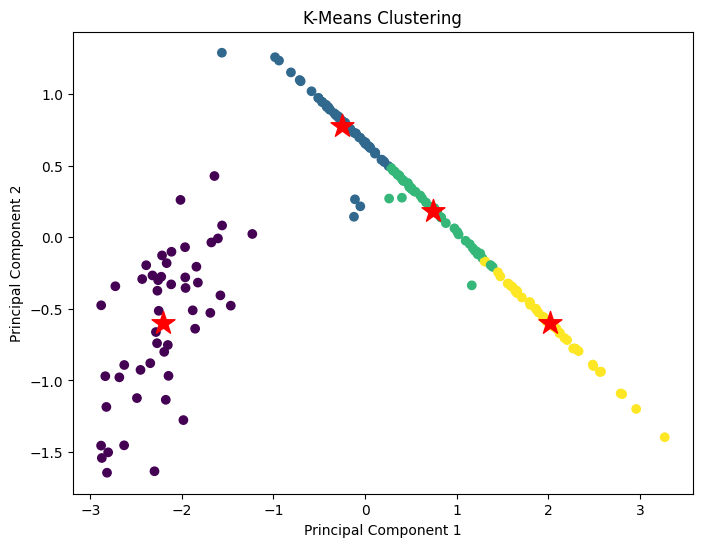

In [51]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
C_pca = pca.transform(km.cluster_centers_)

plt.figure(figsize=(8, 6))

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels2, cmap="viridis")
plt.scatter(C_pca[:, 0], C_pca[:, 1], marker="*", s=300, c="red")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering")
plt.show()

The K-Means algorithm groups customers into four clusters based on the similarity of their standardized features. PCA is used to display the three-dimensional feature information in two dimensions. The centroids represent the centers of the clusters.

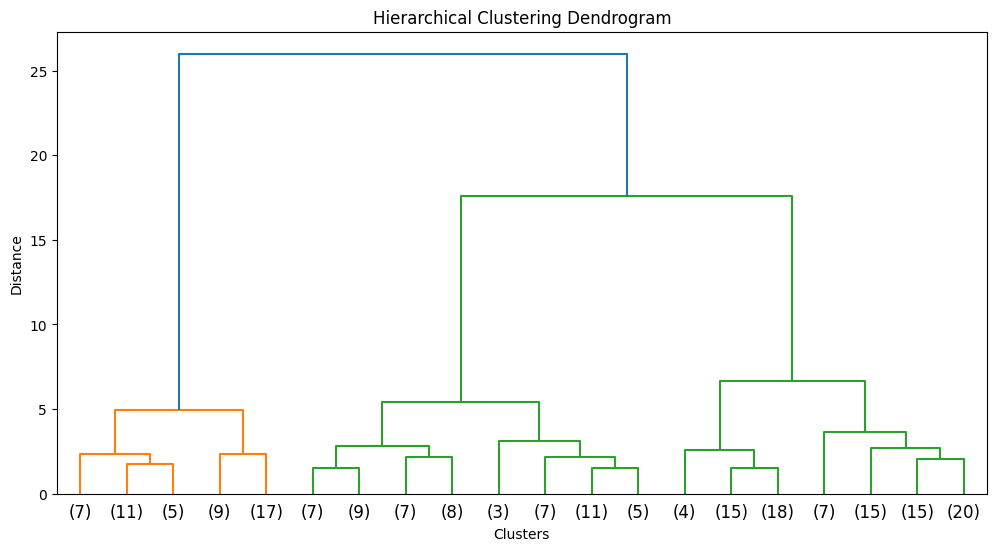

In [52]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode="lastp", p=20)

plt.xlabel("Clusters")
plt.ylabel("Distance")
plt.title("Hierarchical Clustering Dendrogram")
plt.show()

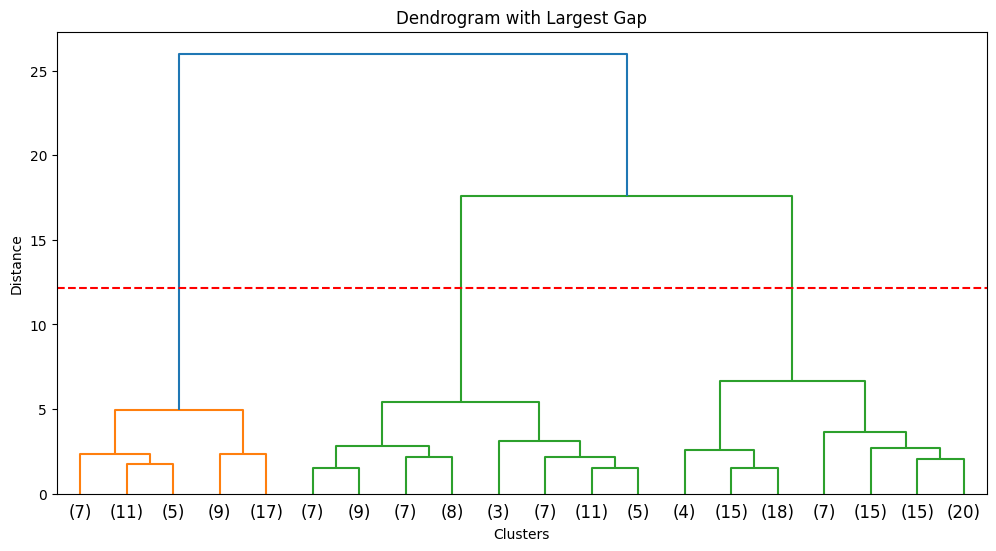

Number of clusters: 3


In [53]:
h = np.sort(Z[:, 2])
gaps = np.diff(h)

i = np.argmax(gaps)
cut = (h[i] + h[i + 1]) / 2

plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode="lastp", p=20)
plt.axhline(cut, color="red", linestyle="--")

plt.xlabel("Clusters")
plt.ylabel("Distance")
plt.title("Dendrogram with Largest Gap")
plt.show()

lab = fcluster(Z, t=cut, criterion="distance")
print("Number of clusters:", len(np.unique(lab)))

The dendrogram represents how clusters are merged at different distances. Large vertical gaps indicate distances where merging would combine relatively dissimilar groups. Cutting the dendrogram at the selected height gives the number of clusters printed above.

In [62]:
lab_h = fcluster(Z, t=4, criterion="maxclust")

print(silhouette_score(X_scaled, lab_h))
print( davies_bouldin_score(X_scaled, lab_h))

0.4558981601935836
0.6848316916795553


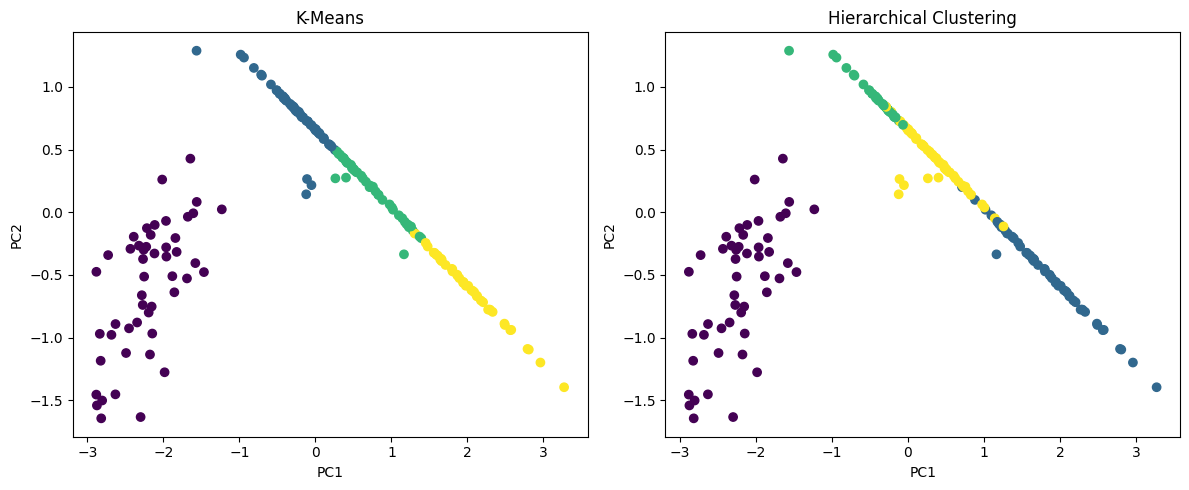

In [63]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels2, cmap="viridis")
plt.title("K-Means")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.subplot(1, 2, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=lab_h, cmap="viridis")
plt.title("Hierarchical Clustering")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.tight_layout()
plt.show()

Both algorithms group customers according to the distances between their feature values. K-Means calculates cluster centroids, whereas hierarchical clustering builds a hierarchy of merged groups. Their cluster assignments may differ because the algorithms use different procedures. The scatter plots help compare their overall group structure.

In [67]:
df["Cluster"] = labels2

profile = df.groupby("Cluster").agg(cluster_size=("age", "count"), mean_age=("age", "mean"), mean_annual_spend=("annual_spend", "mean"), mean_purchase_freq=("purchase_freq", "mean")).round(2)

display(profile)

,cluster_size,mean_age,mean_annual_spend,mean_purchase_freq
Cluster,,,,
0,49,42.54,1467.43,23.31
1,61,69.68,3165.67,39.36
2,46,69.86,4802.65,64.35
3,44,70.00,7959.13,85.61


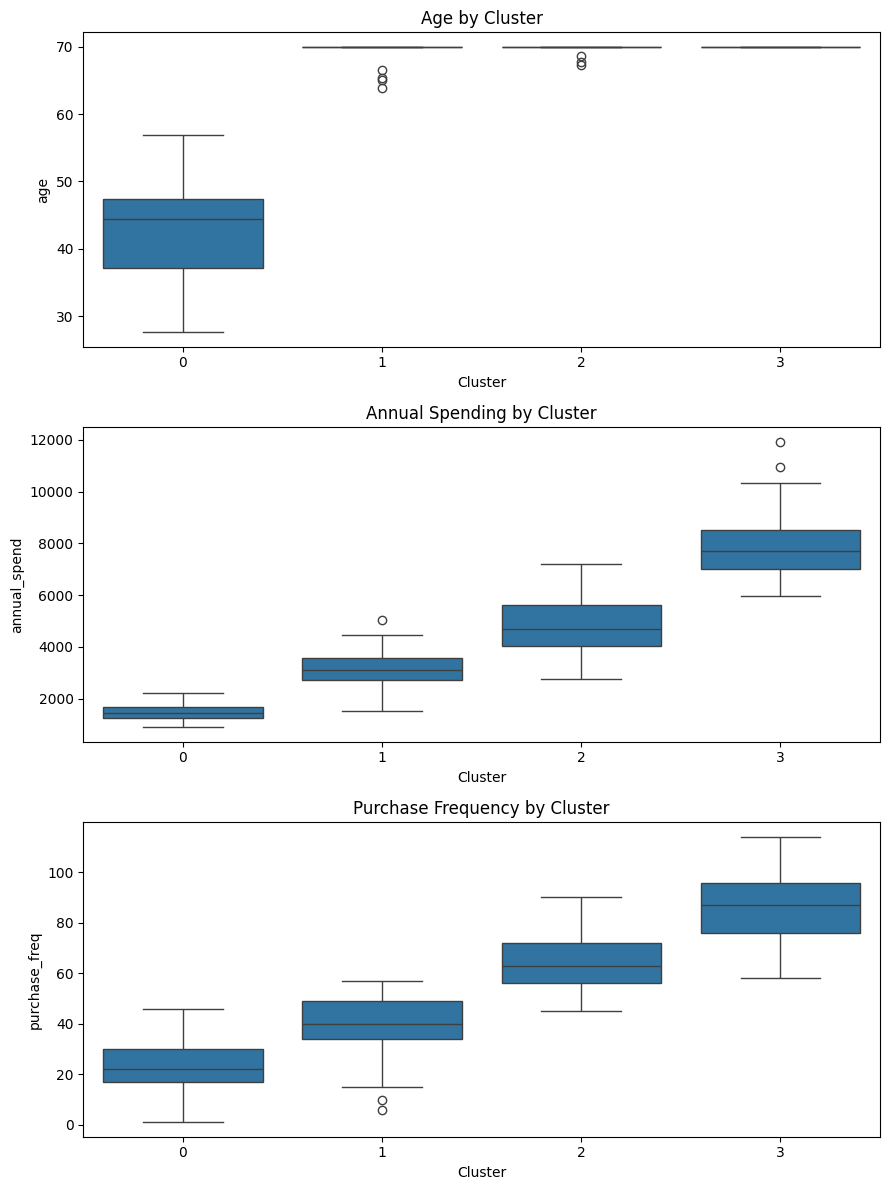

In [57]:
fig, ax = plt.subplots(3, 1, figsize=(9, 12))

sns.boxplot(data=df, x="Cluster", y="age", ax=ax[0])
sns.boxplot(data=df, x="Cluster", y="annual_spend", ax=ax[1])
sns.boxplot(data=df, x="Cluster", y="purchase_freq", ax=ax[2])

ax[0].set_title("Age by Cluster")
ax[1].set_title("Annual Spending by Cluster")
ax[2].set_title("Purchase Frequency by Cluster")

plt.tight_layout()
plt.show()

The cluster profile table shows the average age, annual spending, and purchase frequency for each customer segment. Clusters with high spending and frequent purchases can be described as high-value customers. Clusters with lower spending and fewer purchases may represent occasional customers. The final descriptions should be based on the actual values in the profile table.

In [ ]:
results = pd.DataFrame({
    "Metric": ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"],
    "K-Means": [ silhouette_score(X_scaled, labels2),davies_bouldin_score(X_scaled, labels2),calinski_harabasz_score(X_scaled, labels2)
    ],
    "Hierarchical": [silhouette_score(X_scaled, lab_h),davies_bouldin_score(X_scaled, lab_h), calinski_harabasz_score(X_scaled, lab_h)
    ]
})

display(results.round(4))

,Metric,K-Means,Hierarchical
0,Silhouette,0.4656,0.4559
1,Davies-Bouldin,0.7127,0.6848
2,Calinski-Harabasz,424.7626,398.1290


Silhouette and Calinski-Harabasz scores are generally better when higher, while the Davies-Bouldin index is better when lower. I compare all three metrics to decide which algorithm produces better-defined clusters for this dataset. K-Means is generally more scalable, while hierarchical clustering provides a dendrogram that helps visualize relationships between clusters.

In [64]:
km_raw = KMeans(n_clusters=4, n_init=10, random_state=42)
raw_labels = km_raw.fit_predict(df[["age", "annual_spend", "purchase_freq"]])

print("Raw WCSS:", km_raw.inertia_)
print("Raw Silhouette:", silhouette_score(
    df[["age", "annual_spend", "purchase_freq"]], raw_labels
))

print( km.inertia_)
print( silhouette_score(X_scaled, labels2))

Raw WCSS: 93782942.94615583
Raw Silhouette: 0.5694180651681591
79.98434279070776
0.4655854835976729


Without scaling, annual spending can dominate the distance calculations because it has a much larger numerical range than the other features. Standardization gives all three features a more comparable influence on clustering. WCSS values from raw and scaled data are not directly comparable because they use different scales.

In [65]:
db = DBSCAN(eps=0.5, min_samples=5)
lab_db = db.fit_predict(X_scaled)

clusters = len(set(lab_db) - {-1})
noise = np.sum(lab_db == -1)

print( clusters)
print( noise)

2
8


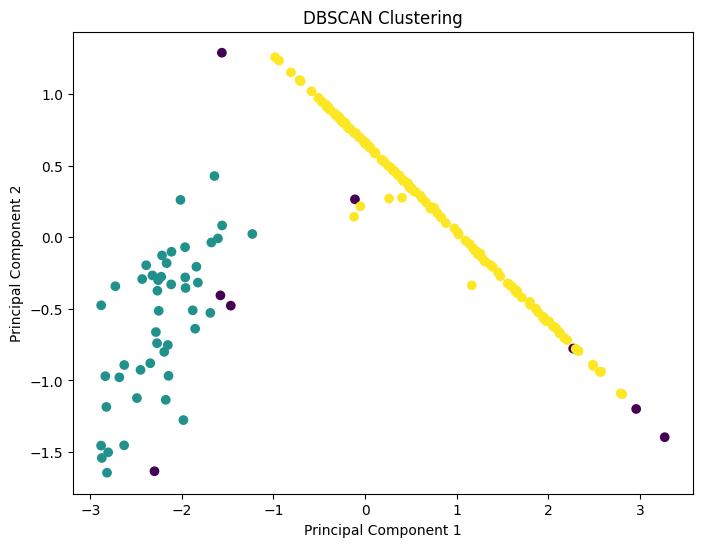

In [66]:
plt.figure(figsize=(8, 6))

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=lab_db, cmap="viridis")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Clustering")
plt.show()

DBSCAN is useful when clusters have irregular shapes and the dataset contains noise or outliers. Unlike K-Means, it does not require the number of clusters to be specified beforehand. However, its performance depends on parameters such as eps and min_samples, and it may not work well when clusters have very different densities.

The three important decisions in a clustering workflow are feature selection, data preprocessing, and choosing a suitable algorithm and its parameters. Feature scaling is important when features have different numerical ranges. The clustering results should be evaluated using metrics and visualizations rather than relying on cluster labels alone. For a real business dataset, I would also investigate missing values and outliers, consult domain experts, and check whether the identified customer segments are useful for business decisions.